# Qiskit Fall Fest 2026 - Vishnu Institute of Technology
## Challenge 4: Quantum Correlation Switch

In this challenge, we build two circuits to demonstrate switching between correlated outcomes (`00` and `11`) and opposite outcomes (`01` and `10`) using a minimal number of quantum gates.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

### Think Before You Run (Predictions)

- **Which outcomes should dominate in Part A?**
  Outcomes `00` and `11` should dominate (~50% each) because of the standard Bell state entangling the qubits.

- **Which outcomes should dominate in Part B?**
  Outcomes `01` and `10` should dominate (~50% each) because the X gate bit-flips qubit 1.

- **Will all four possible outcomes appear?**
  No. In ideal simulation, each circuit only produces 2 entangled states. The other two states have zero probability.

- **Why might some outcomes be much more frequent than others?**
  Because the CNOT gate entangles the qubits, locking their states together. All probability amplitude is concentrated in either the correlated pair ($00, 11$) or the opposite pair ($01, 10$).

In [2]:
# Part A: Correlated Outcomes (00 and 11)
qc_A = QuantumCircuit(2, 2)
qc_A.h(0)
qc_A.cx(0, 1)
qc_A.measure([0, 1], [0, 1])

print(qc_A.draw('text'))

counts_A = simulator.run(qc_A, shots=shots).result().get_counts()
print("\nPart A Results (100 shots):", counts_A)

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Part A Results (100 shots): {'00': 47, '11': 53}


In [3]:
# Part B: Opposite Outcomes (01 and 10)
qc_B = QuantumCircuit(2, 2)
qc_B.h(0)
qc_B.cx(0, 1)
qc_B.x(1)   # Correlation switch: flips qubit 1
qc_B.measure([0, 1], [0, 1])

print(qc_B.draw('text'))

counts_B = simulator.run(qc_B, shots=shots).result().get_counts()
print("\nPart B Results (100 shots):", counts_B)

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Part B Results (100 shots): {'01': 54, '10': 46}


### Part C: Compare Using Histograms

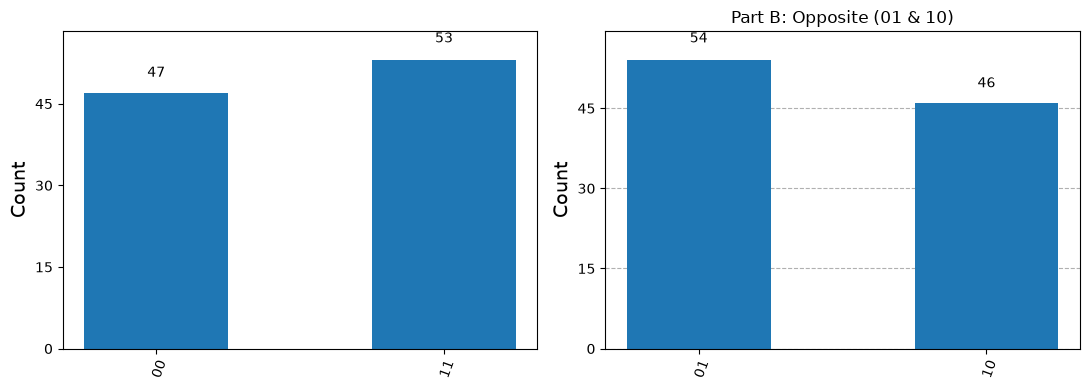

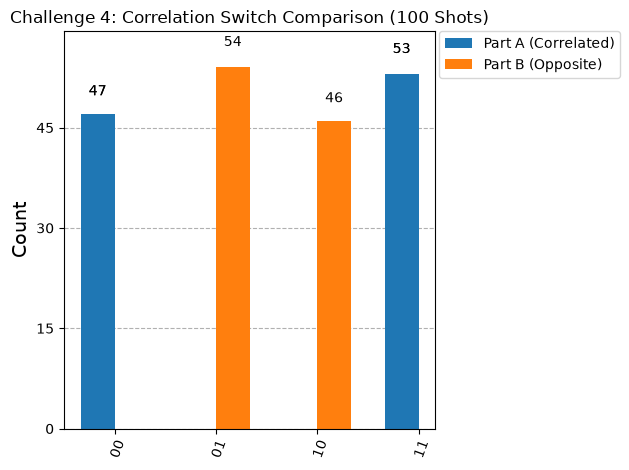

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(counts_A, ax=axes[0], title="Part A: Correlated (00 & 11)")
plot_histogram(counts_B, ax=axes[1], title="Part B: Opposite (01 & 10)")
plt.tight_layout()
plt.show()

plot_histogram([counts_A, counts_B], 
               legend=["Part A (Correlated)", "Part B (Opposite)"], 
               title="Challenge 4: Correlation Switch Comparison (100 Shots)")
plt.show()

### Explanations

- **Which outcomes are dominant in Part A?**
  `00` and `11` are dominant (counts: {'00': 47, '11': 53}).

- **Which outcomes are dominant in Part B?**
  `01` and `10` are dominant (counts: {'01': 54, '10': 46}).

- **What changed between the two circuits?**
  We added an X (NOT) gate on qubit 1 after creating the entangled pair.

- **Why did the measurement relationship change?**
  In Part A, the CNOT gate copies the state of qubit 0 onto qubit 1, giving identical outcomes (00 and 11). In Part B, the X gate acts as a bit-flip on qubit 1, mapping $|00\rangle \to |01\rangle$ and $|11\rangle \to |10\rangle$. This inverts the relationship between the two qubits from correlated to opposite, without destroying the entanglement.